# Telco Customer Churn Prediction

Which telecom customers are likely to cancel, and what drives it?
This notebook explores the Telco Customer Churn dataset, compares three classification models,
handles class imbalance, and evaluates with precision, recall, F1, and ROC-AUC.

## 1. Load and inspect the data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("images", exist_ok=True)
sns.set_theme(style="whitegrid")

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Shape:", df.shape)
print()
print(df.dtypes)
print()
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

Shape: (7043, 21)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


## 2. Clean the data

`TotalCharges` is read as text because a few rows are blank. Those are new customers with `tenure = 0` who have not been billed yet, so the blank value is set to 0.

In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges:", df["TotalCharges"].isna().sum())
print(df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges"]])

df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns="customerID")
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)

print()
print("Duplicate rows:", df.duplicated().sum())
print("Missing values left:", int(df.isna().sum().sum()))

Blank TotalCharges: 11
      customerID  tenure  MonthlyCharges
488   4472-LVYGI       0           52.55
753   3115-CZMZD       0           20.25
936   5709-LVOEQ       0           80.85
1082  4367-NUYAO       0           25.75
1340  1371-DWPAZ       0           56.05
3331  7644-OMVMY       0           19.85
3826  3213-VVOLG       0           25.35
4380  2520-SGTTA       0           20.00
5218  2923-ARZLG       0           19.70
6670  4075-WKNIU       0           73.35
6754  2775-SEFEE       0           61.90

Duplicate rows: 22
Missing values left: 0


## 3. Exploratory analysis

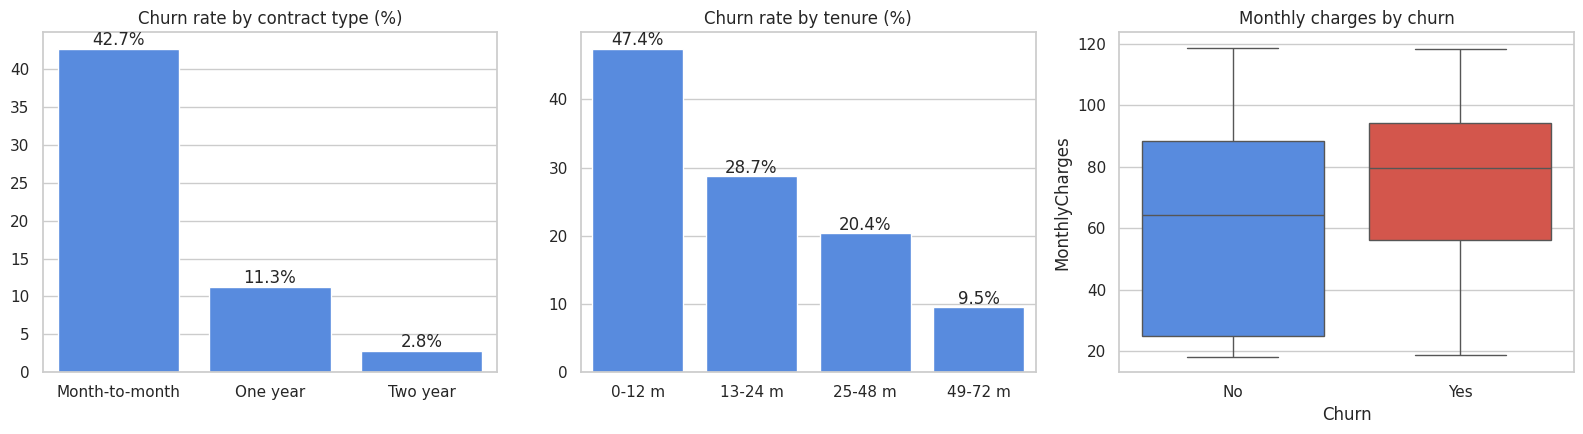

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: churn_rate_%, dtype: float64
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: churn_rate_%, dtype: float64


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# churn rate by contract type
rate = df.groupby("Contract")["churn_flag"].mean().mul(100).sort_values(ascending=False)
sns.barplot(x=rate.index, y=rate.values, ax=axes[0], color="#4285f4")
axes[0].set_title("Churn rate by contract type (%)")
axes[0].set_xlabel("")
for i, v in enumerate(rate.values):
    axes[0].text(i, v + 0.5, f"{v:.1f}%", ha="center")

# churn rate by tenure group
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12 m", "13-24 m", "25-48 m", "49-72 m"])
rate2 = df.groupby("tenure_group", observed=True)["churn_flag"].mean().mul(100)
sns.barplot(x=rate2.index.astype(str), y=rate2.values, ax=axes[1], color="#4285f4")
axes[1].set_title("Churn rate by tenure (%)")
axes[1].set_xlabel("")
for i, v in enumerate(rate2.values):
    axes[1].text(i, v + 0.5, f"{v:.1f}%", ha="center")

# monthly charges by churn
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[2], palette=["#4285f4", "#ea4335"], hue="Churn", legend=False)
axes[2].set_title("Monthly charges by churn")

plt.tight_layout()
plt.savefig("images/eda_churn_drivers.png", dpi=150)
plt.show()

print(df.groupby("InternetService")["churn_flag"].mean().mul(100).round(1).rename("churn_rate_%"))
print(df.groupby("PaymentMethod")["churn_flag"].mean().mul(100).round(1).rename("churn_rate_%"))

## 4. Prepare features and split

- Categorical columns are one-hot encoded.
- The data is split 80/20 with `stratify`, so train and test keep the same churn share (about 26-27%).

In [4]:
from sklearn.model_selection import train_test_split

X = pd.get_dummies(df.drop(columns=["Churn", "churn_flag", "tenure_group"]), drop_first=True).astype(float)
y = df["churn_flag"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Features:", X.shape[1])
print("Train:", X_train.shape, "| churn share:", round(y_train.mean(), 3))
print("Test :", X_test.shape, "| churn share:", round(y_test.mean(), 3))

Features: 30
Train: (5634, 30) | churn share: 0.265
Test : (1409, 30) | churn share: 0.265


## 5. Train and compare models

Because only about a quarter of customers churn, accuracy alone is misleading
(always predicting "no churn" is already about 73% accurate). Models are compared on
precision, recall, F1, and ROC-AUC for the churn class.

Four setups are compared:
1. Logistic regression without any imbalance handling (baseline)
2. Logistic regression with balanced class weights
3. Random forest with balanced class weights
4. Gradient boosting with balanced sample weights

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

models = {
    "Logistic Regression (baseline)": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000)),
    "Logistic Regression (balanced)": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest (balanced)": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced",
        random_state=42, n_jobs=-1),
    "Gradient Boosting (weighted)": GradientBoostingClassifier(random_state=42),
}

fitted, rows = {}, []
for name, model in models.items():
    if name.startswith("Gradient Boosting"):
        model.fit(X_train, y_train, sample_weight=compute_sample_weight("balanced", y_train))
    else:
        model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    fitted[name] = model
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
    })

results = pd.DataFrame(rows).set_index("model").round(3)
results.sort_values("roc_auc", ascending=False)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Gradient Boosting (weighted),0.743,0.510,0.797,0.622,0.843
Random Forest (balanced),0.772,0.553,0.738,0.632,0.843
Logistic Regression (baseline),0.807,0.658,0.567,0.609,0.842
Logistic Regression (balanced),0.740,0.507,0.786,0.616,0.841


## 6. Evaluate the best model

The best model is chosen by ROC-AUC on the test set. With a single train/test split and no
separate validation set, this choice is slightly optimistic, which is noted as a limitation.

Best model: Random Forest (balanced)

              precision    recall  f1-score   support

      Stayed       0.89      0.78      0.83      1035
     Churned       0.55      0.74      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



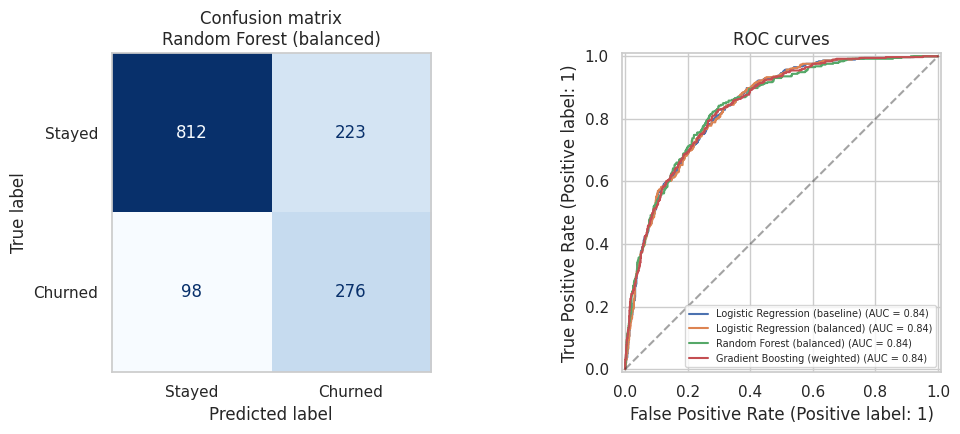

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report

best_name = results["roc_auc"].idxmax()
best = fitted[best_name]
proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
print("Best model:", best_name)
print()
print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stayed", "Churned"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix\n{best_name}")
axes[0].grid(False)
for name, model in fitted.items():
    RocCurveDisplay.from_predictions(y_test, model.predict_proba(X_test)[:, 1], name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set_title("ROC curves")
axes[1].legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.savefig("images/model_evaluation.png", dpi=150)
plt.show()

## 7. Choosing the decision threshold

The default threshold is 0.5. In a retention campaign, missing a churner (low recall) is usually costlier than contacting a loyal customer (low precision), so the trade-off is shown below.

In [7]:
thr_rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (proba >= t).astype(int)
    thr_rows.append({"threshold": t,
                     "precision": precision_score(y_test, p),
                     "recall": recall_score(y_test, p),
                     "f1": f1_score(y_test, p),
                     "customers_flagged": int(p.sum())})
pd.DataFrame(thr_rows).round(3).set_index("threshold")

,precision,recall,f1,customers_flagged
threshold,,,,
0.3,0.451,0.869,0.594,721
0.4,0.512,0.824,0.632,601
0.5,0.553,0.738,0.632,499
0.6,0.604,0.604,0.604,374
0.7,0.684,0.487,0.569,266


## 8. What drives churn?

Permutation importance on the test set: how much the ROC-AUC drops when a feature is shuffled.

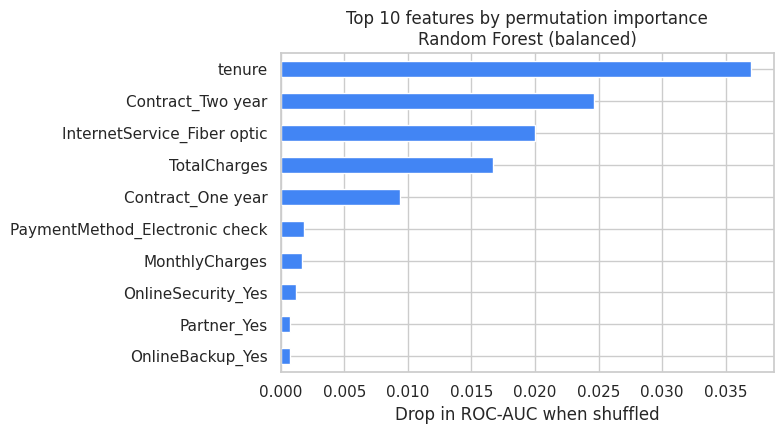

,0
tenure,0.0369
Contract_Two year,0.0246
InternetService_Fiber optic,0.0200
TotalCharges,0.0167
Contract_One year,0.0094
PaymentMethod_Electronic check,0.0018
MonthlyCharges,0.0017
OnlineSecurity_Yes,0.0012
Partner_Yes,0.0007
OnlineBackup_Yes,0.0007


In [8]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(best, X_test, y_test, scoring="roc_auc",
                             n_repeats=5, random_state=42, n_jobs=-1)
importance = (pd.Series(imp.importances_mean, index=X_test.columns)
                .sort_values(ascending=False).head(10))

fig, ax = plt.subplots(figsize=(8, 4.5))
importance[::-1].plot.barh(ax=ax, color="#4285f4")
ax.set_title(f"Top 10 features by permutation importance\n{best_name}")
ax.set_xlabel("Drop in ROC-AUC when shuffled")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=150)
plt.show()

importance.round(4)

## 9. Save the figures

In [9]:
import shutil
shutil.make_archive("images", "zip", "images")
from google.colab import files
files.download("images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>